# Tarea 1. Riesgo de Mercado — Simulación Histórica

**Riesgos Financieros 2027-1**

Se calcula el **VaR** y el **CVaR** a un día del portafolio por **simulación histórica sin alisado** (todos los escenarios pesan igual) y **con alisado** (pesos exponenciales que favorecen los escenarios recientes). Fecha de valuación: **25 de septiembre de 2026**.

| Tipo | Posiciones |
|---|---|
| Acciones (BMV) | +1,000 GCARSO A1 · −10,000 AMX B · +3,000 WALMEX |
| Divisas | +1,500 USD · +1,200 EUR · +0.025 BTC |
| Bonos | CETE 180 d, nominal 15,000 · Bono M cupón 7.5 %, 3,600 d, nominal 1,300 · −1,200 Bondes D, 707 d, cupón cada 28 d |
| Futuros | +100 USD/MXN, K = 18.53, 60 d · −50 Walmart, K = 105, 53 d |
| Swaps TIIE 28 d | Largo: nocional 160 M, paga fija 7.1 %, 588 d · Corto: nocional 120 M, recibe fija 6.9 %, 270 d |
| Opciones de tasa | Call (cap) larga K = 6.9 %, 170 d, 200 M · Put (floor) larga K = 7.0 %, 184 d, 500 M |
| Opciones de tipo de cambio (extra) | Call larga K = 17.50, 110 d, 1,500 USD · Put larga K = 17.90, 90 d, 2,000 USD |

## Metodología

1. **Factores de riesgo.** Para cada posición se arma el histórico de sus factores en las fechas comunes a todas las fuentes: precios (Yahoo Finance), tasas interpoladas por **tasa alambrada** al plazo de cada flujo (archivos del curso) y volatilidades.
2. **Escenarios.** $\Delta X_t=\ln(X_t/X_{t-1})$; el factor simulado es $X^*_t=X_0\,e^{\Delta X_t}$.
3. **Revaluación.** $P\&G_t = V(X^*_t)-V(X_0)$. Para el riesgo por factor se choca sólo ese grupo de factores y el resto se queda en su valor actual; los totales por instrumento y del portafolio usan la revaluación completa.
4. **VaR** = cuantil $1-\alpha$ de la $P\&G$; **CVaR** = promedio (ponderado) de las $P\&G$ por debajo del VaR.
    - Sin alisado: cada escenario pesa $1/N$.
    - Con alisado: el escenario $i$ ($i=1$ el más reciente) pesa $w_0(1-w_0)^{i-1}$, normalizado.

Las cifras están en MXN; el VaR y el CVaR se reportan como $P\&G$ (negativo = pérdida).

## Supuestos

- $\alpha = 98\%$ y $w_0 = 0.05$ (valores de los cuadernos del curso).
- **Precios:** cierre de Yahoo Finance del 25/09/2026; los rendimientos usan el precio ajustado por dividendos (un ex-dividendo no es una pérdida). EUR y BTC se convierten a MXN con el USD/MXN del mismo día.
- **Nocional** del CETE y del Bono M = valor nominal total (1,500 CETES de 10 pesos y 13 Bonos M de 100 pesos); Bondes D: 1,200 títulos de 100 pesos.
- **Futuros:** 1 contrato = 1 unidad del subyacente (1 USD, 1 acción), como en los cuadernos del curso; se valúan como forwards: $(F-K)/(1+r_d\,t/360)$.
- **Bono M:** cupón semestral (182 d), valuado con su tasa *yield* (`tasa_yield.txt`), un factor de riesgo.
- **Bonde D:** el cupón vigente combina la tasa de fondeo ya devengada (21 de 28 días) con la tasa de fondeo actual; los cupones futuros usan la tasa de fondeo actual capitalizada a 28 días; se descuenta con curva gubernamental + sobretasa.
- **Swaps:** cupón variable proyectado con la curva DIRS (tasa forward entre fechas de pago; el primer cupón con la tasa spot) y descuento con la curva TIIE, como en los cuadernos del curso. Pagos cada 28 días contados hacia atrás desde el vencimiento.
- **Opciones de tasa:** Black-76 sobre la tasa forward de 28 días (DIRS), descuento con la curva TIIE y ajuste por pago anticipado. La volatilidad sale de la **superficie por Delta** (`tvoltiie_opc_superficie.txt`): la banda se elige por iteración de punto fijo Delta → banda → volatilidad (según qué tan dentro o fuera del dinero está la opción) y se interpola linealmente en plazo.
- **Opciones de tipo de cambio:** Garman-Kohlhagen; tasa doméstica = curva `tasa_fwd`, extranjera = SOFR. `tvol_usdmxn_historica.txt` sólo trae la volatilidad ATM por plazo (sin eje Delta), así que la superficie disponible tiene una sola banda (Δ = 50); se usa la misma función de bandas que en las opciones de tasa.
- **Futuro de Walmart:** tasa de dividendos fija en 0 (no hay serie histórica); se descuenta con la curva gubernamental (pagarés).
- La **tasa alambrada** se aplica a todas las tasas; las volatilidades se interpolan linealmente. SOFR se trata como tasa simple anual (act/360).

In [1]:
import os
import numpy as np
import pandas as pd
from scipy.stats import norm

FECHA_VAL = pd.Timestamp("2026-09-25")   # fecha de valuación
ALPHA = 0.98                             # nivel de confianza
W0 = 0.05                                # factor de alisado
RUTA = "https://raw.githubusercontent.com/pikey-msc/RiesgosFinancieros/master/2027-1/Tarea/"
pc = 28                                  # periodo de cupón (días) de Bondes D, swaps y opciones de tasa

In [2]:
def talamb(nodos, curva, plazos):
    """Tasa alambrada: interpola manteniendo constante la tasa forward entre nodos.
    `curva` es un vector de nodos o una matriz fechas × nodos; fuera de rango se usa el nodo extremo."""
    nodos, curva = np.asarray(nodos, float), np.asarray(curva, float)
    p = np.clip(np.atleast_1d(np.asarray(plazos, float)), nodos[0], nodos[-1])
    i = np.clip(np.searchsorted(nodos, p) - 1, 0, len(nodos) - 2)
    t1, t2 = nodos[i], nodos[i + 1]
    f1, f2 = 1 + curva[..., i] * t1 / 360, 1 + curva[..., i + 1] * t2 / 360
    return (f1 * (f2 / f1) ** ((p - t1) / (t2 - t1)) - 1) * 360 / p


def lineal(nodos, curva, plazos):
    """Interpolación lineal en plazo (volatilidades); fuera de rango se usa el nodo extremo."""
    nodos, curva = np.asarray(nodos, float), np.asarray(curva, float)
    p = np.clip(np.atleast_1d(np.asarray(plazos, float)), nodos[0], nodos[-1])
    i = np.clip(np.searchsorted(nodos, p) - 1, 0, len(nodos) - 2)
    w = (p - nodos[i]) / (nodos[i + 1] - nodos[i])
    return curva[..., i] * (1 - w) + curva[..., i + 1] * w


def black(F, K, vol, T, phi):
    """Black-76 sin descontar; phi = 1 para call/cap y -1 para put/floor."""
    d1 = (np.log(F / K) + vol**2 * T / 2) / (vol * np.sqrt(T))
    return phi * (F * norm.cdf(phi * d1) - K * norm.cdf(phi * (d1 - vol * np.sqrt(T))))


def var_cvar(pg, w):
    """VaR: primer escenario (de peor a mejor) cuyo peso acumulado alcanza 1 - ALPHA.
    CVaR: promedio ponderado de los escenarios por debajo del VaR."""
    orden = np.argsort(pg)
    v, wo = pg[orden], w[orden]
    k = np.argmax(np.cumsum(wo) / wo.sum() >= round(1 - ALPHA, 10))
    return v[k], (np.average(v[:k], weights=wo[:k]) if k else v[k])


# Verificación de las funciones
nod, cur = np.array([1.0, 30, 90]), np.array([0.05, 0.06, 0.07])
assert np.allclose(talamb(nod, cur, nod), cur)                       # en un nodo regresa la tasa del nodo
assert np.isclose(talamb(nod, cur, 200)[0], 0.07)                    # fuera de rango: nodo extremo
assert np.isclose(black(0.07, 0.069, 0.2, 0.5, 1) - black(0.07, 0.069, 0.2, 0.5, -1), 0.001)  # paridad put-call
assert var_cvar(np.arange(1.0, 101), np.ones(100)) == (2.0, 1.0)     # 100 escenarios: VaR 98 % = 2° peor
print("Funciones verificadas")

Funciones verificadas


## Datos

Curvas del curso (`2027-1/Tarea`) y precios de Yahoo Finance. Se usan sólo las fechas que existen en **todas** las fuentes; la fila 0 es la fecha de valuación. Los precios descargados se guardan en `precios_yahoo.csv` para que el cálculo sea reproducible.

In [3]:
def curva(archivo, escala=1):
    """Archivo de curvas del curso (fila 0 = nodos, columna 0 = fecha) → (nodos, DataFrame fechas × nodos)."""
    d = pd.read_table(RUTA + archivo)
    d.columns = d.columns.str.strip()
    d.index = pd.to_datetime(d.pop(d.columns[0]).astype(str), format="%Y%m%d")
    return d.columns.astype(float).to_numpy(), d.astype(float) / escala


n_gub, gub = curva("tasa_guber.txt")                # cupón cero gubernamental (CETE, Bonde D, futuro Walmart)
n_st, st = curva("tasa_guber_st.txt")               # sobretasa de Bondes D
n_yld, yld = curva("tasa_yield.txt")                # yield de Bonos M
n_tiie, tiie = curva("tasa_TIIE_SW_OP.txt", 100)    # descuento de swaps y opciones de tasa (en %)
n_dirs, dirs = curva("tasa_DIRS_SW_OP.txt", 100)    # cupón variable de swaps y opciones de tasa (en %)
n_fwd, fwd = curva("tasa_fwd.txt", 100)             # tasa doméstica implícita en forwards de tipo de cambio (en %)
n_sofr, sofr = curva("tasa_sofr.txt", 100)          # tasa extranjera USD (en %)
n_vfx, volfx = curva("tvol_usdmxn_historica.txt")   # volatilidad ATM USD/MXN por plazo

sup = pd.read_table(RUTA + "tvoltiie_opc_superficie.txt")
sup.columns = sup.columns.str.strip()
sup.index = pd.to_datetime(sup.pop("DATE").astype(str), format="%Y%m%d")
bandas_tiie = {int(b): g.drop(columns="DELTA").astype(float) for b, g in sup.groupby("DELTA")}
n_vtiie = bandas_tiie[50].columns.astype(float).to_numpy()

tf = pd.read_table(RUTA + "tfondeo.txt")
tf.index = pd.to_datetime(tf["fecha"].astype(str), format="%Y%m%d")
tf = tf["tfondeo"].astype(float).div(100).sort_index().asfreq("D").ffill()   # fines de semana: última tasa

print("Bandas de Delta de la superficie TIIE:", list(bandas_tiie))
print(f"Curvas del {gub.index.min():%d/%m/%Y} al {gub.index.max():%d/%m/%Y}")

Bandas de Delta de la superficie TIIE: [10, 25, 40, 50, 60, 75, 90]
Curvas del 24/09/2025 al 25/09/2026


In [4]:
SIMBOLOS = ["GCARSOA1.MX", "AMXB.MX", "WALMEX.MX", "USDMXN=X", "EURUSD=X", "BTC-USD"]

if os.path.exists("precios_yahoo.csv"):
    precios = pd.read_csv("precios_yahoo.csv", index_col=0, parse_dates=True)
else:
    import yfinance as yf
    yh = yf.download(SIMBOLOS, start="2025-09-01", end="2026-09-26", auto_adjust=False, progress=False, threads=False)
    yh.index = pd.to_datetime(yh.index.date)
    adj, cierre = yh["Adj Close"][SIMBOLOS], yh["Close"][SIMBOLOS]
    # rendimientos con precios ajustados por dividendos, anclados al cierre real de la fecha de valuación
    precios = adj * cierre.loc[FECHA_VAL] / adj.loc[FECHA_VAL]
    precios.to_csv("precios_yahoo.csv")

precios["EURMXN"] = precios["EURUSD=X"] * precios["USDMXN=X"]
precios["BTCMXN"] = precios["BTC-USD"] * precios["USDMXN=X"]

fechas = precios.dropna().index
for c in [gub, st, yld, tiie, dirs, fwd, sofr, volfx, bandas_tiie[50]]:
    fechas = fechas.intersection(c.index)
fechas = fechas[fechas <= FECHA_VAL].sort_values(ascending=False)    # fila 0 = fecha de valuación
assert fechas[0] == FECHA_VAL
n = len(fechas)
P = precios.loc[fechas]
print(f"{n} fechas comunes ({fechas[-1]:%d/%m/%Y} a {fechas[0]:%d/%m/%Y}) → {n - 1} escenarios históricos")
P.head(3)

249 fechas comunes (24/09/2025 a 25/09/2026) → 248 escenarios históricos


,GCARSOA1.MX,AMXB.MX,WALMEX.MX,USDMXN=X,EURUSD=X,BTC-USD,EURMXN,BTCMXN
2026-09-25,141.059998,19.50,46.599998,17.738680,1.137475,84034.921875,20.177309,1.490669e+06
2026-09-24,137.589996,19.57,46.020000,17.541300,1.138187,84379.062500,19.965284,1.480118e+06
2026-09-23,136.500000,19.34,45.810001,17.285601,1.144794,84383.007812,19.788443,1.458611e+06


## Motor de simulación histórica

`agregar` recibe la función de valuación de una posición y los históricos de sus factores agrupados (p. ej. *cupón* y *valor presente* en un swap). Revalúa la posición en cada escenario con todos los factores (P&G total) y con cada grupo aislado (P&G por factor de riesgo), y la guarda en `POS` para integrar después por instrumento, por factor y para el portafolio.

In [5]:
POS = []   # (tipo de instrumento, posición, V0, {grupo: P&G}, {grupo: tipo de factor})


def agregar(tipo, posicion, valuar, bloques):
    """bloques: [(grupo, tipo de factor, histórico n × k alineado a `fechas`, o None si el factor es fijo)]."""
    X = np.hstack([np.asarray(h, float).reshape(n, -1) for _, _, h in bloques if h is not None])
    x0, dX = X[0], np.log(X[:-1] / X[1:])
    Xs = x0 * np.exp(dX)                                        # X* = X0·e^ΔX, un renglón por escenario
    V0 = float(valuar(x0))
    pg, tipos, j = {"Total": valuar(Xs) - V0}, {}, 0
    for grupo, tipo_factor, h in bloques:
        k = 0 if h is None else np.asarray(h).reshape(n, -1).shape[1]
        solo = np.zeros(X.shape[1], bool)
        solo[j:j + k] = True
        j += k
        pg[grupo] = valuar(np.where(solo, Xs, x0)) - V0         # sólo se choca este grupo
        tipos[grupo] = tipo_factor
    POS.append((tipo, posicion, V0, pg, tipos))
    return V0

## Acciones y divisas

Un factor por posición: su precio en MXN. $V = q\cdot S$.

In [6]:
for tipo, nombre, col, q in [("Acciones", "Gcarso", "GCARSOA1.MX", 1000),
                             ("Acciones", "América Móvil", "AMXB.MX", -10000),
                             ("Acciones", "Walmart", "WALMEX.MX", 3000),
                             ("Divisas", "USD", "USDMXN=X", 1500),
                             ("Divisas", "EUR", "EURMXN", 1200),
                             ("Divisas", "Bitcoin", "BTCMXN", 0.025)]:
    V0 = agregar(tipo, nombre, lambda x, q=q: q * x[..., 0], [(nombre, tipo, P[col])])
    print(f"{nombre:14s} {q:>10,} × {P[col].iloc[0]:>14,.4f} = {V0:>14,.2f}")

Gcarso              1,000 ×       141.0600 =     141,060.00
América Móvil     -10,000 ×        19.5000 =    -195,000.00
Walmart             3,000 ×        46.6000 =     139,800.00
USD                 1,500 ×        17.7387 =      26,608.02
EUR                 1,200 ×        20.1773 =      24,212.77
Bitcoin             0.025 × 1,490,668.5784 =      37,266.71


## Bonos

- **CETE:** $V = N/(1+r_{180}\cdot 180/360)$ con la curva gubernamental.
- **Bono M:** $V=\big[N\,c\,\tfrac{182}{360}\,a(y)+N\,u^{-n}\big]\,u^{\,1-p_1/182}$, con $u = 1+y\cdot 182/360$, $a(y)=\frac{1-u^{-n}}{y\cdot182/360}$, $n$ cupones y $p_1$ días al primer cupón (precio sucio).
- **Bonde D:** $V=\sum_i \dfrac{N\,c_i\,\tfrac{28}{360} + N\,\mathbb{1}_{i=n}}{1+(r_{p_i}+s_{p_i})\,p_i/360}$, con $c_1=\big[\prod_{\text{días devengados}}(1+tf_d/360)\,(1+tf/360)^{28-d}-1\big]\tfrac{360}{28}$ y $c_{i>1}=\big[(1+tf/360)^{28}-1\big]\tfrac{360}{28}$.

In [7]:
# CETE: cupón cero, nominal 15,000, 180 días, curva gubernamental
V0 = agregar("Bonos", "CETE 180 d", lambda x: 15000 / (1 + x[..., 0] * 180 / 360),
             [("Tasa gubernamental", "Tasa de interés", talamb(n_gub, gub.loc[fechas], 180))])
print(f"CETE: tasa {talamb(n_gub, gub.loc[FECHA_VAL], 180)[0]:.4%}, valor {V0:,.2f}")


# Bono M: cupón 7.5 % semestral (182 d), 3,600 d, nominal 1,300, valuado con su yield
def bono_m(y, nominal=1300, cupon=0.075, plazo=3600, pcm=182):
    N = (plazo - 1) // pcm + 1                    # cupones por pagar
    p1 = plazo - pcm * (N - 1)                    # días al primer cupón
    u = 1 + y * pcm / 360
    a = (1 - u ** -N) / (y * pcm / 360)
    return (nominal * cupon * pcm / 360 * a + nominal * u ** -N) * u ** (1 - p1 / pcm)


V0 = agregar("Bonos", "Bono M 3,600 d", lambda x: bono_m(x[..., 0]),
             [("Tasa yield", "Tasa de interés", talamb(n_yld, yld.loc[fechas], 3600))])
print(f"Bono M: yield {talamb(n_yld, yld.loc[FECHA_VAL], 3600)[0]:.4%}, valor {V0:,.2f} "
      f"(precio sucio {V0 / 13:,.4f} por título de 100)")

# Bonde D corto: 1,200 títulos de 100, 707 días, cupón cada 28 días referido a la tasa de fondeo
N_bd = (707 - 1) // pc + 1
t_bd = 707 - pc * np.arange(N_bd)[::-1]          # 7, 35, ..., 707
ddv = pc - t_bd[0]                               # días ya devengados del cupón vigente
fac_dev = np.prod(1 + tf.loc[FECHA_VAL - pd.Timedelta(days=ddv):FECHA_VAL - pd.Timedelta(days=1)] / 360)


def bonde(x, titulos=-1200, nominal=100):
    tfo, r, s = x[..., :1], x[..., 1:N_bd + 1], x[..., N_bd + 1:]
    cup_fut = ((1 + tfo / 360) ** pc - 1) * 360 / pc                       # fondeo capitalizado 28 días
    cup_vig = (fac_dev * (1 + tfo / 360) ** (pc - ddv) - 1) * 360 / pc    # devengado + resto del periodo
    cup = np.concatenate([cup_vig, np.repeat(cup_fut, N_bd - 1, axis=-1)], axis=-1)
    flujo = cup * pc / 360 + (np.arange(N_bd) == N_bd - 1)               # el último flujo paga el nominal
    return titulos * nominal * (flujo / (1 + (r + s) * t_bd / 360)).sum(-1)


V0 = agregar("Bonos", "Bonde D 707 d (corto)", bonde,
             [("Tasa de fondeo", "Tasa de interés", tf.loc[fechas]),
              ("Tasa gubernamental", "Tasa de interés", talamb(n_gub, gub.loc[fechas], t_bd)),
              ("Sobretasa", "Tasa de interés", talamb(n_st, st.loc[fechas], t_bd))])
print(f"Bonde D: {N_bd} cupones, {ddv} días devengados, fondeo {tf[FECHA_VAL]:.2%}, valor {V0:,.2f}")

CETE: tasa 6.3150%, valor 14,540.87
Bono M: yield 5.9334%, valor 1,462.65 (precio sucio 112.5119 por título de 100)
Bonde D: 26 cupones, 21 días devengados, fondeo 6.55%, valor -117,161.52


## Futuros

$F = S\,\dfrac{1+r_d\,t/360}{1+r_f\,t/360}$ y $V = \text{contratos}\cdot\dfrac{F-K}{1+r_d\,t/360}$. En el futuro de dólar $r_f$ es SOFR y $r_d$ la curva `tasa_fwd`; en el de Walmart $r_f$ es la tasa de dividendos y $r_d$ la curva gubernamental.

In [8]:
def forward(S, rd, rf, t, K):
    """Valor por unidad de un forward: (F − K) descontado, con F = S·(1 + rd·t/360)/(1 + rf·t/360)."""
    return (S * (1 + rd * t / 360) / (1 + rf * t / 360) - K) / (1 + rd * t / 360)


V0 = agregar("Futuros", "USD/MXN largo", lambda x: 100 * forward(x[..., 0], x[..., 1], x[..., 2], 60, 18.53),
             [("Tipo de cambio", "Divisas", P["USDMXN=X"]),
              ("Tasa doméstica (fwd)", "Tasa de interés", talamb(n_fwd, fwd.loc[fechas], 60)),
              ("Tasa extranjera (SOFR)", "Tasa de interés", talamb(n_sofr, sofr.loc[fechas], 60))])
print(f"Futuro USD/MXN: valor {V0:,.2f}")

Q_DIV = 0.0   # tasa de dividendos de Walmart (fija)
V0 = agregar("Futuros", "Walmart corto", lambda x: -50 * forward(x[..., 0], x[..., 1], Q_DIV, 53, 105),
             [("Precio Walmart", "Acciones", P["WALMEX.MX"]),
              ("Tasa gubernamental (pagarés)", "Tasa de interés", talamb(n_gub, gub.loc[fechas], 53)),
              ("Tasa de dividendos (fija)", "Tasa de interés", None)])
print(f"Futuro Walmart: valor {V0:,.2f}")

Futuro USD/MXN: valor -71.36
Futuro Walmart: valor 2,872.65


## Swaps de TIIE

$\text{IRS} = \pm M\sum_i \dfrac{(f_i - t_f)\,28/360}{1+r_{p_i}\,p_i/360}$ (+ si se paga fija). $f_1$ es la tasa spot de la curva DIRS al primer pago y $f_i=\Big[\dfrac{1+r^{c}_{p_i}p_i/360}{1+r^{c}_{p_{i-1}}p_{i-1}/360}-1\Big]\dfrac{360}{28}$; $r_{p_i}$ sale de la curva TIIE. Factores: los cupones proyectados y las tasas de descuento de cada flujo.

In [9]:
def swap(nombre, nocional, tasa_fija, plazo, paga_fija):
    N = (plazo - 1) // pc + 1
    t = plazo - pc * np.arange(N)[::-1]                       # fechas de pago (días)
    r = talamb(n_dirs, dirs.loc[fechas], t)                   # curva de cupón variable a cada pago
    cupon = np.hstack([r[:, :1],                              # primer cupón: tasa spot
                       ((1 + r[:, 1:] * t[1:] / 360) / (1 + r[:, :-1] * t[:-1] / 360) - 1) * 360 / pc])
    signo = 1 if paga_fija else -1
    V0 = agregar("Swaps", nombre,
                 lambda x: signo * nocional * ((x[..., :N] - tasa_fija) * pc / 360 / (1 + x[..., N:] * t / 360)).sum(-1),
                 [("Cupón (DIRS)", "Tasa de interés", cupon),
                  ("Valor presente (TIIE)", "Tasa de interés", talamb(n_tiie, tiie.loc[fechas], t))])
    print(f"{nombre}: {N} cupones (primero a {t[0]} d), valor {V0:,.2f}")


swap("Largo: paga fija 7.1 %", 160e6, 0.071, 588, True)
swap("Corto: recibe fija 6.9 %", 120e6, 0.069, 270, False)

Largo: paga fija 7.1 %: 21 cupones (primero a 28 d), valor -1,716,322.12
Corto: recibe fija 6.9 %: 10 cupones (primero a 18 d), valor 186,442.55


## Opciones de tasa de interés (superficie de volatilidad por Delta)

Caplet/floorlet de un flujo con Black-76: $V = M\,\phi\,[S\,N(\phi d_1)-K\,N(\phi d_2)]\,\dfrac{1}{1+r\,t/360}\,\dfrac{28/360}{1+S\cdot 28/360}$, con $S$ la tasa forward de 28 días que inicia en $t$ (curva DIRS), $r$ la tasa TIIE de descuento, $\phi=1$ cap y $-1$ floor.

La volatilidad depende de qué tan dentro o fuera del dinero está la opción: se parte de la banda Δ = 50, se calcula el Delta $N(\phi d_1)$ con esa volatilidad, se toma la banda más cercana y se repite hasta que la banda no cambia. El histórico de esa banda (interpolada al plazo) es el factor de volatilidad.

In [10]:
def banda_delta(bandas, nodos, t, F, K, phi):
    """Banda de Delta de la superficie por iteración de punto fijo: Delta → banda → volatilidad → Delta."""
    b = 50
    for _ in range(10):
        vol = lineal(nodos, bandas[b].loc[FECHA_VAL], t)[0]
        delta = 100 * norm.cdf(phi * (np.log(F / K) + vol**2 * t / 730) / (vol * np.sqrt(t / 365)))
        b, anterior = min(bandas, key=lambda d: abs(d - delta)), b
        if b == anterior:
            break
    return b, delta, vol


def opcion_tasa(nombre, nocional, K, t, phi):
    d = talamb(n_tiie, tiie.loc[fechas], t)                                   # descuento al vencimiento
    r1, r2 = talamb(n_dirs, dirs.loc[fechas], t), talamb(n_dirs, dirs.loc[fechas], t + pc)
    S = ((1 + r2 * (t + pc) / 360) / (1 + r1 * t / 360) - 1) * 360 / pc       # forward de 28 d que inicia en t
    b, delta, vol0 = banda_delta(bandas_tiie, n_vtiie, t, S[0, 0], K, phi)
    V0 = agregar("Opciones de tasa", nombre,
                 lambda x: nocional * black(x[..., 1], K, x[..., 2], t / 365, phi) / (1 + x[..., 0] * t / 360)
                 * (pc / 360) / (1 + x[..., 1] * pc / 360),
                 [("Valor presente (TIIE)", "Tasa de interés", d),
                  ("Tasa subyacente (forward DIRS)", "Tasa de interés", S),
                  ("Volatilidad", "Volatilidad", lineal(n_vtiie, bandas_tiie[b].loc[fechas], t))])
    dentro = "dentro" if phi * (S[0, 0] - K) > 0 else "fuera"
    print(f"{nombre}: forward {S[0, 0]:.4%} vs strike {K:.2%} ({dentro} del dinero), Delta {delta:.1f} → banda {b}, "
          f"vol {vol0:.2%}, valor {V0:,.2f}")


opcion_tasa("Call larga K 6.9 %", 200e6, 0.069, 170, 1)
opcion_tasa("Put larga K 7.0 %", 500e6, 0.070, 184, -1)

Call larga K 6.9 %: forward 6.6546% vs strike 6.90% (fuera del dinero), Delta 44.6 → banda 40, vol 24.28%, valor 50,282.89
Put larga K 7.0 %: forward 6.6012% vs strike 7.00% (dentro del dinero), Delta 60.7 → banda 60, vol 23.33%, valor 252,755.85


## Opciones de tipo de cambio (puntos extra)

Garman-Kohlhagen escrito sobre el forward: $V = \text{USD}\cdot\dfrac{\phi\,[F\,N(\phi d_1)-K\,N(\phi d_2)]}{1+r_d\,t/360}$, con $F = S\,\dfrac{1+r_d\,t/360}{1+r_f\,t/360}$. La volatilidad se resuelve con la misma función de bandas de Delta; el archivo de volatilidad USD/MXN sólo trae la banda ATM, por lo que la banda resultante es Δ = 50.

In [11]:
bandas_fx = {50: volfx}   # tvol_usdmxn_historica.txt sólo trae volatilidad ATM por plazo: una banda de Delta


def opcion_tc(nombre, usd, K, t, phi):
    S = P["USDMXN=X"].to_numpy()
    rd, rf = talamb(n_fwd, fwd.loc[fechas], t), talamb(n_sofr, sofr.loc[fechas], t)
    F0 = S[0] * (1 + rd[0, 0] * t / 360) / (1 + rf[0, 0] * t / 360)
    b, delta, vol0 = banda_delta(bandas_fx, n_vfx, t, F0, K, phi)
    V0 = agregar("Opciones de tipo de cambio", nombre,
                 lambda x: usd * black(x[..., 0] * (1 + x[..., 1] * t / 360) / (1 + x[..., 2] * t / 360),
                                       K, x[..., 3], t / 365, phi) / (1 + x[..., 1] * t / 360),
                 [("Tipo de cambio", "Divisas", S),
                  ("Tasa doméstica (fwd)", "Tasa de interés", rd),
                  ("Tasa extranjera (SOFR)", "Tasa de interés", rf),
                  ("Volatilidad", "Volatilidad", lineal(n_vfx, bandas_fx[b].loc[fechas], t))])
    dentro = "dentro" if phi * (F0 - K) > 0 else "fuera"
    print(f"{nombre}: spot {S[0]:.4f}, forward {F0:.4f} vs strike {K:.2f} ({dentro} del dinero), "
          f"Delta {delta:.1f} → banda {b}, vol {vol0:.2%}, valor {V0:,.2f}")


opcion_tc("Call larga K 17.50", 1500, 17.50, 110, 1)
opcion_tc("Put larga K 17.90", 2000, 17.90, 90, -1)

Call larga K 17.50: spot 17.7387, forward 17.8621 vs strike 17.50 (dentro del dinero), Delta 71.6 → banda 50, vol 6.76%, valor 707.61


Put larga K 17.90: spot 17.7387, forward 17.8397 vs strike 17.90 (dentro del dinero), Delta 53.4 → banda 50, vol 6.66%, valor 525.04


## Resultados

VaR y CVaR al 98 % a un día, por posición, por factor de riesgo de cada posición, por tipo de instrumento, por tipo de factor de riesgo (sumando la P&G de los grupos de ese tipo en todas las posiciones) y del portafolio (revaluación completa).

In [12]:
w_sin = np.ones(n - 1)                          # sin alisado: pesos iguales
w_con = W0 * (1 - W0) ** np.arange(n - 1)       # con alisado: escenario 0 = el más reciente


def medidas(pg):
    (v1, c1), (v2, c2) = var_cvar(pg, w_sin), var_cvar(pg, w_con)
    return {"VaR sin alisado": v1, "VaR con alisado": v2, "CVaR sin alisado": c1, "CVaR con alisado": c2}


filas = []
for tipo in dict.fromkeys(p[0] for p in POS):
    del_tipo = [p for p in POS if p[0] == tipo]
    for _, posicion, V0, pg, tipos in del_tipo:
        if len(tipos) == 1:
            filas.append({"Instrumento": tipo, "Posición": posicion, "Factor de riesgo": posicion,
                          "Valor": V0, **medidas(pg["Total"])})
            continue
        for g in tipos:
            filas.append({"Instrumento": tipo, "Posición": posicion, "Factor de riesgo": g, **medidas(pg[g])})
        filas.append({"Instrumento": tipo, "Posición": posicion, "Factor de riesgo": f"Total {posicion}",
                      "Valor": V0, **medidas(pg["Total"])})
    filas.append({"Instrumento": tipo, "Posición": "", "Factor de riesgo": f"Total {tipo}",
                  "Valor": sum(p[2] for p in del_tipo), **medidas(sum(p[3]["Total"] for p in del_tipo))})

FACTORES = ["Acciones", "Divisas", "Tasa de interés", "Volatilidad"]
pg_factor = {f: sum(pg[g] for *_, pg, tipos in POS for g in tipos if tipos[g] == f) for f in FACTORES}
pg_port = sum(p[3]["Total"] for p in POS)
for f in FACTORES:
    filas.append({"Instrumento": "Total por factor de riesgo", "Posición": "", "Factor de riesgo": f,
                  **medidas(pg_factor[f])})
filas.append({"Instrumento": "Total por factor de riesgo", "Posición": "", "Factor de riesgo": "Portafolio",
              "Valor": sum(p[2] for p in POS), **medidas(pg_port)})

res = pd.DataFrame(filas)
num = ["Valor", "VaR sin alisado", "VaR con alisado", "CVaR sin alisado", "CVaR con alisado"]
res.style.format("{:,.2f}", subset=num, na_rep="").hide(axis="index")

Instrumento,Posición,Factor de riesgo,Valor,VaR sin alisado,VaR con alisado,CVaR sin alisado,CVaR con alisado
Acciones,Gcarso,Gcarso,"141,060.00","-7,600.46","-4,378.45","-9,092.59","-7,861.66"
Acciones,América Móvil,América Móvil,"-195,000.00","-8,550.90","-4,530.19","-11,598.24","-7,162.46"
Acciones,Walmart,Walmart,"139,800.00","-3,965.55","-3,664.11","-4,632.14","-4,114.21"
Acciones,,Total Acciones,"85,859.99","-10,381.71","-6,595.15","-11,597.71","-9,381.89"
Divisas,USD,USD,"26,608.02",-295.74,-169.74,-401.77,-218.08
Divisas,EUR,EUR,"24,212.77",-235.60,-107.42,-255.60,-149.54
Divisas,Bitcoin,Bitcoin,"37,266.71","-2,391.06","-1,083.34","-3,458.40","-1,393.87"
Divisas,,Total Divisas,"88,087.51","-2,507.02","-1,040.32","-3,468.24","-1,476.88"
Bonos,CETE 180 d,CETE 180 d,"14,540.87",-7.96,-5.10,-11.26,-8.29
Bonos,"Bono M 3,600 d","Bono M 3,600 d","1,462.65",-23.94,-29.89,-32.25,-49.58


In [13]:
port = medidas(pg_port)
por_tipo = res[res["Factor de riesgo"].str.startswith("Total ") & (res["Posición"] == "")]
suma = por_tipo[["VaR sin alisado", "VaR con alisado", "CVaR sin alisado", "CVaR con alisado"]].sum()
print(f"Valor del portafolio: {sum(p[2] for p in POS):,.2f}")
for m in suma.index:
    print(f"{m:17s} portafolio {port[m]:>14,.2f} | suma por tipo de instrumento {suma[m]:>14,.2f} | "
          f"beneficio de diversificación {port[m] - suma[m]:>12,.2f}")
peores = pd.Series(pg_port, index=fechas[:-1]).nsmallest(6)
print("\nPeores escenarios del portafolio (fecha del cambio y P&G):")
print(peores.map("{:,.2f}".format).to_string())

Valor del portafolio: -1,150,017.39
VaR sin alisado   portafolio    -190,850.45 | suma por tipo de instrumento    -255,970.98 | beneficio de diversificación    65,120.53
VaR con alisado   portafolio     -95,977.34 | suma por tipo de instrumento    -167,113.17 | beneficio de diversificación    71,135.84
CVaR sin alisado  portafolio    -277,005.09 | suma por tipo de instrumento    -369,994.33 | beneficio de diversificación    92,989.23
CVaR con alisado  portafolio    -114,232.18 | suma por tipo de instrumento    -247,391.29 | beneficio de diversificación   133,159.11

Peores escenarios del portafolio (fecha del cambio y P&G):
2026-03-12    -390,053.09
2025-11-05    -288,405.31
2026-01-02    -232,322.48
2025-10-09    -197,239.49
2026-03-06    -190,850.45
2025-09-29    -190,055.46


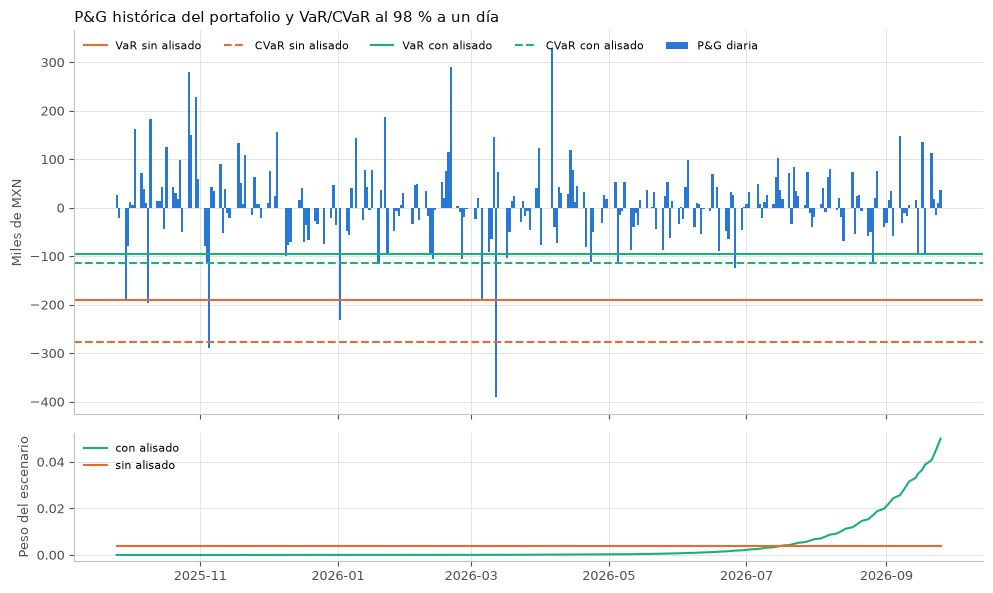

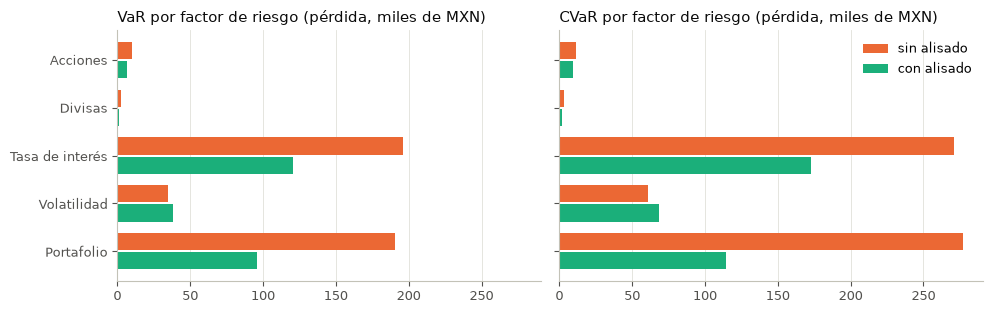

In [14]:
import matplotlib.pyplot as plt

AZUL, NARANJA, AQUA = "#2a78d6", "#eb6834", "#1baf7a"   # paleta categórica validada, orden fijo
plt.rcParams.update({"axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#52514e", "xtick.color": "#52514e",
                     "ytick.color": "#52514e", "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
                     "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False, "font.size": 9})

fig, (a1, a2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
a1.bar(fechas[:-1], pg_port / 1e3, width=1.0, color=AZUL, label="P&G diaria")
for etiqueta, color in [("sin alisado", NARANJA), ("con alisado", AQUA)]:
    a1.axhline(port[f"VaR {etiqueta}"] / 1e3, color=color, lw=1.5, label=f"VaR {etiqueta}")
    a1.axhline(port[f"CVaR {etiqueta}"] / 1e3, color=color, lw=1.5, ls="--", label=f"CVaR {etiqueta}")
a1.set_ylabel("Miles de MXN")
a1.set_title("P&G histórica del portafolio y VaR/CVaR al 98 % a un día", loc="left", color="#0b0b0b")
a1.legend(ncol=5, frameon=False, loc="upper left", fontsize=8)
a2.plot(fechas[:-1], w_con / w_con.sum(), color=AQUA, lw=1.5, label="con alisado")
a2.plot(fechas[:-1], w_sin / w_sin.sum(), color=NARANJA, lw=1.5, label="sin alisado")
a2.set_ylabel("Peso del escenario")
a2.legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig("fig_pyg_portafolio.png", dpi=200)
plt.show()

fac = res[res["Instrumento"] == "Total por factor de riesgo"].set_index("Factor de riesgo")
fig, axs = plt.subplots(1, 2, figsize=(10, 3.2), sharex=True, sharey=True)
y = np.arange(len(fac))
for ax, medida in zip(axs, ["VaR", "CVaR"]):
    ax.barh(y - 0.2, -fac[f"{medida} sin alisado"] / 1e3, height=0.36, color=NARANJA, label="sin alisado")
    ax.barh(y + 0.2, -fac[f"{medida} con alisado"] / 1e3, height=0.36, color=AQUA, label="con alisado")
    ax.set_title(f"{medida} por factor de riesgo (pérdida, miles de MXN)", loc="left", color="#0b0b0b")
    ax.grid(axis="y", visible=False)
axs[0].set_yticks(y, fac.index)
axs[0].invert_yaxis()
axs[1].legend(frameon=False, loc="upper right")
fig.tight_layout()
fig.savefig("fig_var_factor.png", dpi=200)
plt.show()

## Interpretación de resultados

**Valor del portafolio.** El portafolio vale −1,150,017 MXN al 25/09/2026. Lo domina el swap largo (−1,716,322): paga 7.1 % fijo mientras la curva DIRS proyecta cupones de entre 6.0 % y 6.8 %. Lo compensan en parte las opciones de tasa (+303,039) y el swap corto (+186,443).

**Riesgo total.** Con 98 % de confianza, la pérdida a un día no debería superar 190,850 MXN según la simulación histórica sin alisado, ni 95,977 MXN con alisado. Cuando se rebasa el VaR, la pérdida promedio (CVaR) es de 277,005 y 114,232 MXN, respectivamente.

**De dónde viene el riesgo.** Casi todo es riesgo de tasa de interés (VaR de −196,019 sin alisado) y, dentro de él, de los swaps (−207,339). El swap largo recibe la tasa variable sobre 160 millones y pierde cuando baja la curva DIRS con la que se proyectan sus cupones (VaR de ese factor: −260,062); el swap corto, que recibe fija, compensa una parte. Los peores días del año son caídas de esa curva: el 12/03/2026 su nodo de 720 días bajó 24 pb (pérdida de 390,053) y el 05/11/2025 toda la curva bajó cerca de 20 pb (−288,405). Siguen la volatilidad de las opciones de tasa (−34,882), las acciones (−10,358) y las divisas (−2,500); bonos, futuros y opciones de tipo de cambio aportan poco porque sus montos son pequeños.

**VaR contra CVaR.** Sin alisado, el CVaR es 45 % mayor que el VaR: la cola izquierda es pesada, con cuatro días cuyas pérdidas (de 197 mil a 390 mil) quedan muy por debajo del cuantil del 2 %. El VaR sólo dice dónde empieza la cola; el CVaR mide qué tan profunda es, y para este portafolio es la medida más informativa. Con alisado la brecha baja a 19 %, porque esos días extremos ocurrieron entre octubre de 2025 y marzo de 2026 y casi no pesan.

**Con alisado contra sin alisado.** Con w0 = 0.05, los 60 escenarios más recientes (julio a septiembre de 2026) concentran 95 % del peso, así que el VaR con alisado describe un periodo más tranquilo en tasas y resulta la mitad del histórico simple. La excepción es la volatilidad: su VaR con alisado (−37,864) supera al sin alisado (−34,882) porque lo fija un escenario reciente, la caída de la volatilidad de las opciones TIIE del 18/09/2026, que con alisado pesa 3.9 % y sin alisado 0.4 %. Lo mismo pasa con el Bono M, cuya yield a 10 años se movió más en los últimos tres meses (desviación diaria de 15 pb contra 10 pb en el año). El alisado reacciona rápido a un cambio de régimen pero olvida las crisis de hace más de tres meses; el VaR sin alisado es más conservador. Para fijar límites o capital conviene el VaR sin alisado (o el mayor de los dos), y el alisado como alerta temprana.

**Diversificación.** La suma de los VaR por tipo de instrumento (−255,971) es mayor que el VaR del portafolio (−190,850): diversificar ahorra 25 % del VaR y del CVaR. Se ve dentro de cada grupo: el corto en América Móvil compensa los largos en Gcarso y Walmart (VaR de las acciones −10,382 contra −20,117 sumando cada una), el swap corto compensa al largo, y el call y el put de tipo de cambio forman una posición casi neutral al dólar con gamma positiva, de modo que su VaR conjunto (−45) es sólo de volatilidad, contra −181 y −171 de cada opción por separado.

**Limitaciones.** La simulación histórica supone que el día siguiente se parecerá a alguno de los últimos 248. Los futuros se tomaron con una unidad de subyacente por contrato; con los tamaños de MexDer (10,000 USD y 100 acciones) su riesgo crecería en esa proporción. La volatilidad de tipo de cambio disponible es sólo ATM, sin sonrisa por Delta.

In [15]:
# Mismo texto de la interpretación, para la hoja Notas del Excel
INTERPRETACION = [
    ('Valor del portafolio. El portafolio vale −1,150,017 MXN al 25/09/2026. Lo domina el swap largo '
     '(−1,716,322): paga 7.1 % fijo mientras la curva DIRS proyecta cupones de entre 6.0 % y 6.8 %. Lo '
     'compensan en parte las opciones de tasa (+303,039) y el swap corto (+186,443).'),
    ('Riesgo total. Con 98 % de confianza, la pérdida a un día no debería superar 190,850 MXN según la '
     'simulación histórica sin alisado, ni 95,977 MXN con alisado. Cuando se rebasa el VaR, la pérdida '
     'promedio (CVaR) es de 277,005 y 114,232 MXN, respectivamente.'),
    ('De dónde viene el riesgo. Casi todo es riesgo de tasa de interés (VaR de −196,019 sin alisado) y, '
     'dentro de él, de los swaps (−207,339). El swap largo recibe la tasa variable sobre 160 millones y '
     'pierde cuando baja la curva DIRS con la que se proyectan sus cupones (VaR de ese factor: −260,062); '
     'el swap corto, que recibe fija, compensa una parte. Los peores días del año son caídas de esa curva: '
     'el 12/03/2026 su nodo de 720 días bajó 24 pb (pérdida de 390,053) y el 05/11/2025 toda la curva bajó '
     'cerca de 20 pb (−288,405). Siguen la volatilidad de las opciones de tasa (−34,882), las acciones '
     '(−10,358) y las divisas (−2,500); bonos, futuros y opciones de tipo de cambio aportan poco porque '
     'sus montos son pequeños.'),
    ('VaR contra CVaR. Sin alisado, el CVaR es 45 % mayor que el VaR: la cola izquierda es pesada, con '
     'cuatro días cuyas pérdidas (de 197 mil a 390 mil) quedan muy por debajo del cuantil del 2 %. El VaR '
     'sólo dice dónde empieza la cola; el CVaR mide qué tan profunda es, y para este portafolio es la '
     'medida más informativa. Con alisado la brecha baja a 19 %, porque esos días extremos ocurrieron '
     'entre octubre de 2025 y marzo de 2026 y casi no pesan.'),
    ('Con alisado contra sin alisado. Con w0 = 0.05, los 60 escenarios más recientes (julio a septiembre '
     'de 2026) concentran 95 % del peso, así que el VaR con alisado describe un periodo más tranquilo en '
     'tasas y resulta la mitad del histórico simple. La excepción es la volatilidad: su VaR con alisado '
     '(−37,864) supera al sin alisado (−34,882) porque lo fija un escenario reciente, la caída de la '
     'volatilidad de las opciones TIIE del 18/09/2026, que con alisado pesa 3.9 % y sin alisado 0.4 %. Lo '
     'mismo pasa con el Bono M, cuya yield a 10 años se movió más en los últimos tres meses (desviación '
     'diaria de 15 pb contra 10 pb en el año). El alisado reacciona rápido a un cambio de régimen pero '
     'olvida las crisis de hace más de tres meses; el VaR sin alisado es más conservador. Para fijar '
     'límites o capital conviene el VaR sin alisado (o el mayor de los dos), y el alisado como alerta '
     'temprana.'),
    ('Diversificación. La suma de los VaR por tipo de instrumento (−255,971) es mayor que el VaR del '
     'portafolio (−190,850): diversificar ahorra 25 % del VaR y del CVaR. Se ve dentro de cada grupo: el '
     'corto en América Móvil compensa los largos en Gcarso y Walmart (VaR de las acciones −10,382 contra '
     '−20,117 sumando cada una), el swap corto compensa al largo, y el call y el put de tipo de cambio '
     'forman una posición casi neutral al dólar con gamma positiva, de modo que su VaR conjunto (−45) es '
     'sólo de volatilidad, contra −181 y −171 de cada opción por separado.'),
    ('Limitaciones. La simulación histórica supone que el día siguiente se parecerá a alguno de los '
     'últimos 248. Los futuros se tomaron con una unidad de subyacente por contrato; con los tamaños de '
     'MexDer (10,000 USD y 100 acciones) su riesgo crecería en esa proporción. La volatilidad de tipo de '
     'cambio disponible es sólo ATM, sin sonrisa por Delta.'),
]

In [16]:
from openpyxl import Workbook
from openpyxl.styles import Alignment, Font

wb = Workbook()
ws = wb.active
ws.title = "Valores"
negrita = Font(bold=True)
encabezado = {
    "E1": "Valor en Riesgo", "O1": "Valor en Riesgo Condicional", "D2": "Valor",
    "E2": "Simulación Histórica", "G2": "Delta Normal", "H2": "Delta Gamma Normal", "J2": "Simulación Montecarlo",
    "O2": "Simulación Histórica", "Q2": "Delta Normal", "R2": "Delta Gamma Normal", "T2": "Simulación Montecarlo",
    "A3": "Instrumento", "B3": "Instrumento Ind", "C3": "Factor Riesgo", "E3": "Sin alisado", "F3": "Con Alisado",
    "G3": "Delta Normal", "H3": "Delta Gamma Normal", "I3": "Delta Gamma Cornish Fisher", "J3": "Cholesky Normal",
    "K3": "Cholesky Empírica", "L3": "CP Normal", "M3": "CP Empírica", "O3": "Sin alisado", "P3": "Con Alisado",
    "Q3": "Delta Normal", "R3": "Delta Gamma Normal", "S3": "Delta Gamma Cornish Fisher", "T3": "Cholesky Normal",
    "U3": "Cholesky Empírica", "V3": "CP Normal", "W3": "CP Empírica"}
for celda, texto in encabezado.items():
    ws[celda] = texto
    ws[celda].font = negrita
for rango in ["E1:M1", "O1:W1", "E2:F2", "H2:I2", "J2:M2", "O2:P2", "R2:S2", "T2:W2"]:
    ws.merge_cells(rango)

columnas = {"Valor": "D", "VaR sin alisado": "E", "VaR con alisado": "F",
            "CVaR sin alisado": "O", "CVaR con alisado": "P"}
i = 4
for fila in res.to_dict("records"):
    por_factor = fila["Instrumento"] == "Total por factor de riesgo"
    if por_factor and fila["Factor de riesgo"] == FACTORES[0]:
        i += 1                                                   # renglón en blanco y encabezado de la sección
        ws[f"A{i}"] = "Total por factor de riesgo"
        ws[f"A{i}"].font = negrita
        i += 1
    total = por_factor or fila["Factor de riesgo"].startswith("Total")
    if not total:
        ws[f"A{i}"], ws[f"B{i}"] = fila["Instrumento"], fila["Posición"]
    ws[f"C{i}"] = fila["Factor de riesgo"]
    for campo, col in columnas.items():
        if pd.notna(fila[campo]):
            ws[f"{col}{i}"] = round(float(fila[campo]), 2)
            ws[f"{col}{i}"].number_format = "#,##0.00"
    if total:
        for col in "CDEFOP":
            ws[f"{col}{i}"].font = negrita
    i += 1
ws[f"A{i + 1}"] = ("Cifras en MXN calculadas en Tarea1_RiesgoMercado_SH.ipynb; VaR y CVaR al 98 % a un día "
                   "expresados como P&G (negativo = pérdida). Supuestos e interpretación en la hoja Notas.")
for col, ancho in {"A": 24, "B": 26, "C": 32, "D": 16, "E": 14, "F": 14, "N": 3, "O": 14, "P": 14}.items():
    ws.column_dimensions[col].width = ancho
ws.freeze_panes = "D4"

notas = wb.create_sheet("Notas")
renglones = [
    ("Parámetros", ""),
    ("Fecha de valuación", f"{FECHA_VAL:%d/%m/%Y}"),
    ("Horizonte", "1 día"),
    ("Nivel de confianza", f"{ALPHA:.0%}"),
    ("Factor de alisado (w0)", f"{W0} (peso w0·(1−w0)^(i−1), i = 1 el escenario más reciente)"),
    ("Escenarios históricos", f"{n - 1} cambios diarios entre el {fechas[-1]:%d/%m/%Y} y el {fechas[0]:%d/%m/%Y}"),
    ("Interpolación", "Tasa alambrada para tasas; lineal para volatilidades"),
    ("Unidades", "MXN; VaR y CVaR expresados como P&G (negativo = pérdida)"),
    ("", ""),
    ("Supuestos", ""),
    ("Nocional CETE / Bono M", "Valor nominal total: 15,000 (1,500 CETES de 10) y 1,300 (13 Bonos M de 100)"),
    ("Bondes D", "1,200 títulos de 100 en corto; cupón con tasa de fondeo, descuento con guber + sobretasa"),
    ("Futuros", "1 contrato = 1 unidad del subyacente (1 USD / 1 acción); dividendos de Walmart = 0"),
    ("Swaps", "Cupón proyectado con curva DIRS, descuento con curva TIIE; pagos cada 28 días"),
    ("Opciones de tasa", "Black-76; volatilidad de la superficie por Delta (banda por iteración de punto fijo)"),
    ("Opciones de tipo de cambio", "Garman-Kohlhagen; tvol_usdmxn_historica.txt sólo trae la banda ATM (Delta 50)"),
    ("Precios", "Yahoo Finance; rendimientos con precio ajustado por dividendos"),
]
for r, (a, b) in enumerate(renglones, start=1):
    notas[f"A{r}"], notas[f"B{r}"] = a, b
    if b == "" and a:
        notas[f"A{r}"].font = negrita
r = len(renglones) + 2
notas[f"A{r}"] = "Interpretación"
notas[f"A{r}"].font = negrita
for k, parrafo in enumerate(INTERPRETACION, start=r + 1):
    notas[f"A{k}"] = parrafo
    notas.merge_cells(f"A{k}:B{k}")
    notas[f"A{k}"].alignment = Alignment(wrap_text=True, vertical="top")
    notas.row_dimensions[k].height = 15 * (len(parrafo) // 120 + 1)
notas.column_dimensions["A"].width = 28
notas.column_dimensions["B"].width = 95
wb.properties.creator = ""
wb.save("Resultados_Tarea.xlsx")
print("Resultados guardados en Resultados_Tarea.xlsx")

Resultados guardados en Resultados_Tarea.xlsx
